# **CAVIAR Network Analysis**

In this case study, we will go through and understand a **time-varying criminal network that was repeatedly disrupted by police forces**, and how the criminal network reoriented in response to the seizures of product by the police forces.

--------------------
## **Context**
--------------------
Here is some information on the CAVIAR project and the role of certain individuals arrested following the investigation. **The investigation lasted two years and ran from 1994 to 1996**. The operation was brought together by investigation units of the **Montreal police and the Royal Canadian Mounted Police of Canada**. **During these two years, 11 wiretap warrants, valid for about two months each, were obtained (11 matrices match these phases).**

This case is rather unique because, unlike other investigative strategies, **the mandate of the CAVIAR project was to seize the drugs without arresting criminals**. During this period, imports of the trafficking network were hit and seized by the police on eleven occasions. **The arrests took place only at the end of the investigation**. Monetary losses for traffickers were estimated at 32 million dollars. **Some phases included no seizures, and others included multiple**. Here is what they represent **in terms of the amount of money**:

- Phase 4 - 1 seizure, 2,500,000 Dollars, 300 kg of marijuana
- Phase 6 - 3 seizures, 1,300,000 Dollars, 2 x 15 kg of marijuana + 1 x 2 kg of cocaine
- Phase 7 - 1 seizure, 3,500,000 Dollars, 401 kg of marijuana
- Phase 8 - 1 seizure, 360,000 Dollars, 9 kg of cocaine
- Phase 9 - 2 seizures, 4,300,000 Dollars, 2 kg of cocaine + 1 x 500 kg marijuana
- Phase 10 - 1 seizure, 18,700,000 Dollars, 2200 kg of marijuana
- Phase 11 - 2 seizures, 1,300,000 Dollars, 12 kg of cocaine + 11 kg of cocaine

As you can see, this case study offers a **rare opportunity to study a criminal network in response to upheaval by police forces**. This allows us to analyze changes in the network structure and to survey the reaction and adaptation of the participants while they were subjected to an increasing number of distressing constraints.

------------------------------------
## **About the network**
------------------------------------
The network consists of 110 (numbered) players. Players 1-82 are the traffickers. Players 83-110 are the non-traffickers (financial investors, accountants, owners of various importation businesses, etc.). Initially, the investigation targeted Daniel Serero, the alleged mastermind of a drug network in downtown Montreal, attempting to import marijuana to Canada from Morocco, transiting through Spain. After the first seizure, happening in phase 4, traffickers reoriented to cocaine import from Colombia, transiting through the United States.

According to the police, the role of the players of the "Serero organization" under investigation were the following:

- Daniel Serero (N1) - Mastermind of the network
- Pierre Perlini (N3) - Principal lieutenant of Serero, executes instructions
- Alain (N83) and G'erard (N86) Levy - Investors and transporters of money
- Wallace Lee (N85) - Takes care of financial affairs (accountant)
- Gaspard Lino (N6) - Broker in Spain
- Samir Rabbat (N11) - Provider in Morocco
- Lee Gilbert (N88) - Trusted man of Wallace Lee (became an informer after the arrest)
- Beverly Ashton (N106) - Spouse of Lino, transports money and documents
- Antonio Iannacci (N89) - Investor
- Mohammed Echouafni (N84) - Moroccan investor
- Richard Gleeson (N5), Bruno de Quinzio (N8), and Gabrielle Casale (N76) - Charged with recuperating the marijuana
- Roderik Janouska (N77) - Individual with airport contacts
- Patrick Lee (N87) - Investor
- Salvatore Panetta (N82) - Transport arrangements manager
- Steve Cunha (N96) - Transport manager, owner of a legitimate import company (became an informer after the arrest)
- Ernesto Morales (N12) - Principal organizer of the cocaine import, an intermediary between the Colombians and the Serero organization
- Oscar Nieri (N17) - The handyman of Morales
- Richard Brebner (N80) - Transporting the cocaine from the US to Montreal
- Ricardo Negrinotti (N33) - Taking possession of the cocaine in the US to hand it to Brebner
- Johnny Pacheco (N16) - Cocaine provider

-----------------------
## **Objective**
-----------------------
- The objective of the case study is to **understand, create, and visualize the data in phases**.
- Later on, we will **apply different network centrality measures** and understand the important nodes of the network.
- We will **visualize the centrality measures** of the important nodes across phases.

## **Importing the required libraries**

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
%matplotlib inline

import networkx as nx

from decorator import decorator

from networkx.utils import create_random_state, create_py_random_state

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

import warnings

# To get rid of warning messages
warnings.filterwarnings('ignore')

# Remove scientific notations and display numbers with 2 decimal points instead
pd.options.display.float_format = '{ : , .2f}'.format

# Update default background style of plots
sns.set_style(style = 'darkgrid')

## **Loading the data from 11 phases**

In [8]:
path = "/content/drive/MyDrive/trainings/MIT/notebook/w03/02/CAVIAR_Phases/"

P1 = pd.read_csv(path + "phase1.csv")

P2 = pd.read_csv(path + "/phase2.csv")

P3 = pd.read_csv(path + "phase3.csv")

P4 = pd.read_csv(path + "phase4.csv")

P5 = pd.read_csv(path + "phase5.csv")

P6 = pd.read_csv(path + "phase6.csv")

P7 = pd.read_csv(path + "phase7.csv")

P8 = pd.read_csv( path + "phase8.csv")

P9 = pd.read_csv( path + "phase9.csv")

P10 = pd.read_csv( path + "phase10.csv")

P11 = pd.read_csv( path + "phase11.csv")

In [11]:
P1.head()

,Unnamed: 0,1,4,89,83,3,5,88,85,90,2,7,54,6,64,8
0,1,0,1,4,0,4,2,2,9,1,2,0,2,0,1,1
1,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,89,1,0,0,0,0,0,0,0,0,0,3,0,0,0,0
3,83,1,0,0,0,0,0,0,0,0,0,0,0,5,0,0
4,3,2,0,0,0,0,0,1,0,0,0,0,0,0,0,0


So, we have the data in the form of an adjacency matrix represented through a DataFrame.

**Observations:**

- The first column (Unnamed: 0) needs to be set as the index.
- The column names and the indices should have the same data type.

Let us check the points above.

In [12]:
# Setting first column as the index to achieve the adjacency matrix for each phase
# Defining a list with the phases
phases = [P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11]

# Now, let us set the first column as the index for all the DataFrames
for p in phases:
    p.set_index(p.columns[0], inplace = True)

In [13]:
P1

,1,4,89,83,3,5,88,85,90,2,7,54,6,64,8
Unnamed: 0,,,,,,,,,,,,,,,
1,0,1,4,0,4,2,2,9,1,2,0,2,0,1,1
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
89,1,0,0,0,0,0,0,0,0,0,3,0,0,0,0
83,1,0,0,0,0,0,0,0,0,0,0,0,5,0,0
3,2,0,0,0,0,0,1,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
88,1,0,0,0,1,0,0,3,0,0,0,0,1,0,0
85,1,0,0,0,0,0,2,0,0,0,0,0,5,0,0
90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Now, that we have set the index, check for the consistency in column names and indices data type
P1.index, P1.columns

(Int64Index([1, 4, 89, 83, 3, 5, 88, 85, 90, 2, 7, 54, 6, 64, 8], dtype='int64', name='Unnamed: 0'),
 Index(['1', '4', '89', '83', '3', '5', '88', '85', '90', '2', '7', '54', '6',
        '64', '8'],
       dtype='object'))

**Observation:**

- The above output shows that the indices are of integer data type and the column names are of object data type.
- Let's convert the column names to integer data types.

In [14]:
# Let's convert the column names to integer types
phases = [P1, P2, P3, P4, P5, P6, P7, P8, P9, P10, P11]

col = []

for p in phases:                 # Running the loop for each phase (11)
    for i in p.columns:          # Running the loop for each column of each phase
        col.append(int(i))       # Appending column names to the list 'col'
    p.columns = col              # Updating the column names for each phase
    col = []                     # Reinitiating the list 'col' as an empty list

In [15]:
# Let's check if the transformation worked
P1.index, P1.columns

(Index([1, 4, 89, 83, 3, 5, 88, 85, 90, 2, 7, 54, 6, 64, 8], dtype='int64', name='Unnamed: 0'),
 Index([1, 4, 89, 83, 3, 5, 88, 85, 90, 2, 7, 54, 6, 64, 8], dtype='int64'))

**Observation:**

- We observe that the transformation has worked. Both, indices as well as column names, are of integer data type.  

## **Generating Graphs**

Now, that we have created the adjacency matrices, let us now try to create graphs out of these adjacency matrices.

- We will use the from_pandas_adjacency function and pass the adjacency matrix for each phase as a DataFrame.

In [16]:
graphs = []

for i, p in enumerate(phases):
    g = 'graph' + str(i + 1)

    print(g)

    g = nx.from_pandas_adjacency(p)

    graphs.append(g)

    print(g.nodes())

graph1
[1, 4, 89, 83, 3, 5, 88, 85, 90, 2, 7, 54, 6, 64, 8]
graph2
[1, 89, 83, 3, 5, 88, 85, 90, 86, 2, 7, 6, 64, 8, 55, 10, 56, 97, 47, 98, 76, 9, 11, 12]
graph3
[1, 4, 89, 83, 3, 5, 48, 88, 85, 90, 86, 2, 7, 6, 8, 55, 10, 56, 76, 9, 34, 35, 11, 32, 84, 49, 107, 50, 99, 13, 51, 12, 52]
graph4
[1, 4, 89, 83, 3, 5, 88, 85, 90, 86, 2, 7, 6, 8, 47, 76, 9, 35, 11, 53, 84, 49, 107, 13, 51, 63, 109, 31, 12, 14, 52, 106, 15]
graph5
[1, 4, 89, 83, 3, 5, 88, 85, 86, 2, 7, 6, 8, 55, 47, 76, 9, 34, 11, 32, 84, 13, 31, 12, 108, 100, 18, 17, 25, 82, 19, 15]
graph6
[1, 4, 83, 3, 5, 85, 2, 6, 8, 76, 9, 11, 84, 13, 31, 12, 14, 18, 25, 82, 19, 78, 77, 87, 20, 15]
graph7
[1, 4, 83, 3, 5, 88, 85, 62, 9, 2, 6, 8, 55, 76, 34, 11, 12, 14, 18, 17, 19, 78, 77, 87, 20, 22, 74, 79, 69, 61, 68, 16, 75, 28, 81, 15]
graph8
[1, 4, 83, 3, 85, 86, 2, 6, 8, 76, 9, 34, 35, 11, 84, 13, 12, 14, 18, 17, 25, 82, 19, 78, 77, 87, 20, 22, 16, 28, 81, 67, 38, 73, 39, 59, 37, 23, 33, 80, 91, 36]
graph9
[1, 89, 83, 3, 88, 85, 90

## **Visualizing the Graphs**

Let us now visualize the graphs that we have created above.

### **Note:** In case you face an error while running the below code, please upgrade the decorator library, by running the following code, to resolve the error.

**!pip install --upgrade decorator**

****************************************************************************************
Graph for phase: 1


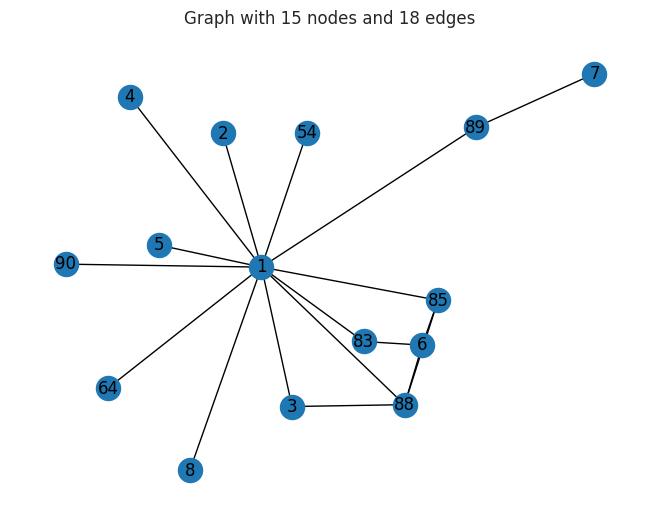

****************************************************************************************
Graph for phase: 2


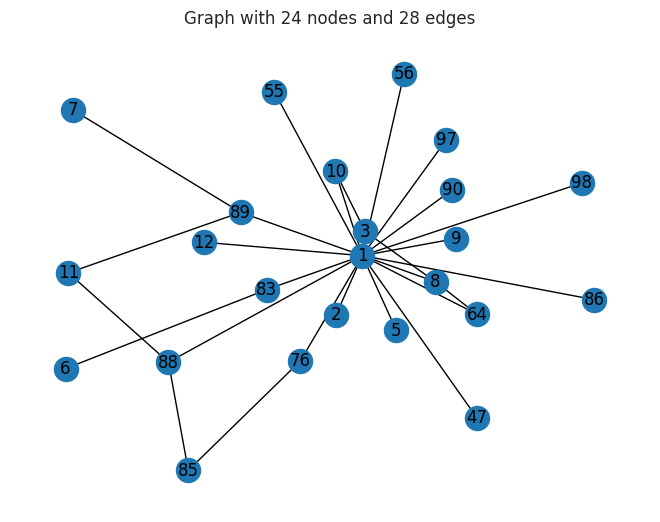

****************************************************************************************
Graph for phase: 3


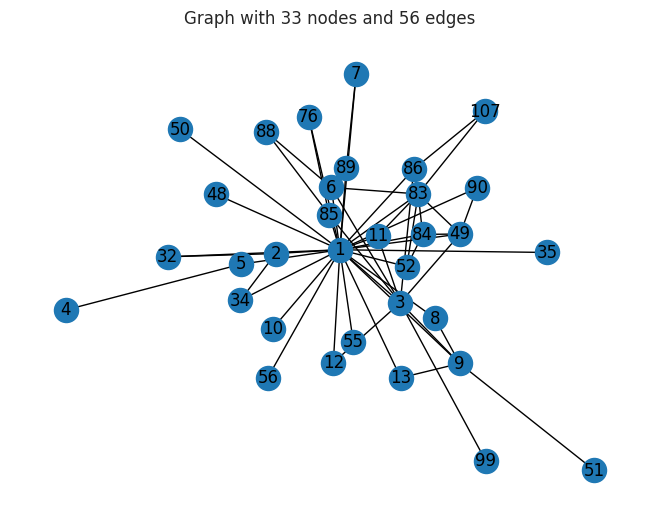

****************************************************************************************
Graph for phase: 4


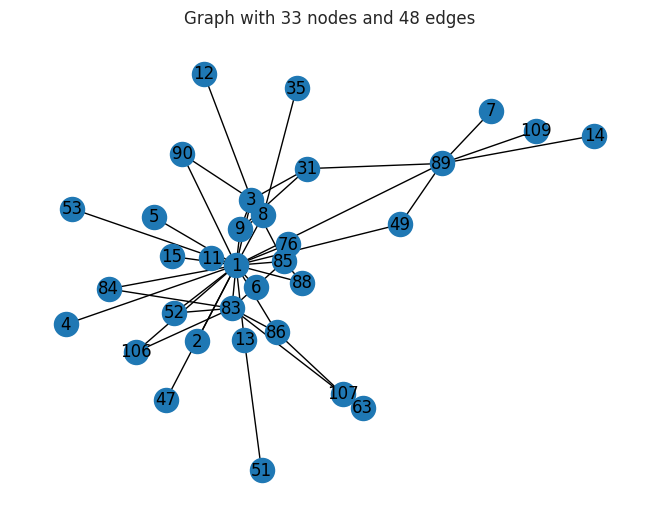

****************************************************************************************
Graph for phase: 5


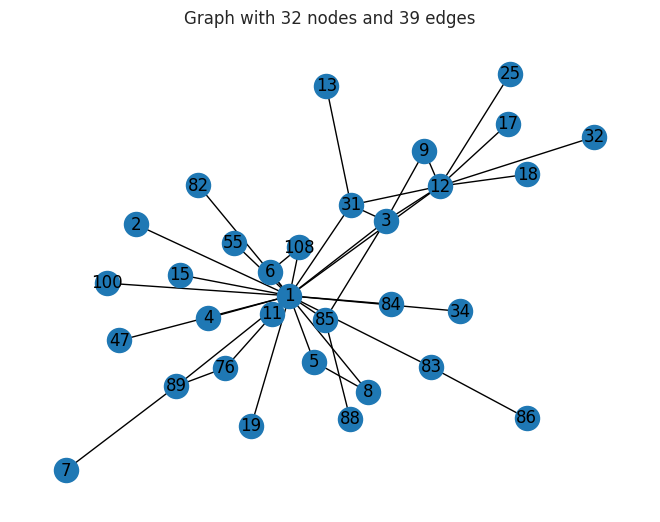

****************************************************************************************
Graph for phase: 6


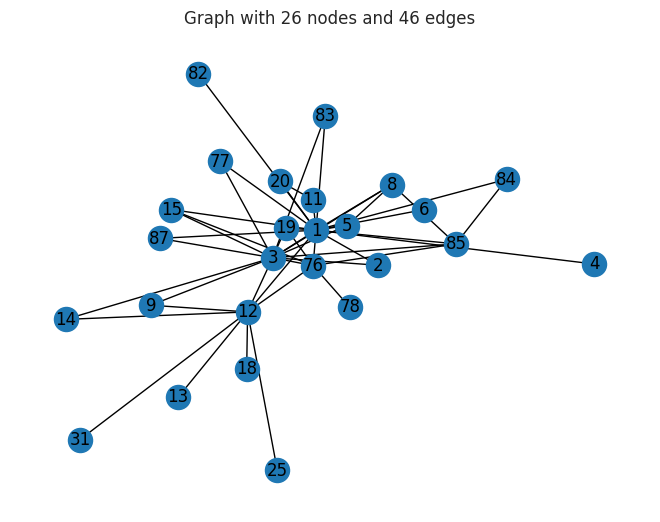

****************************************************************************************
Graph for phase: 7


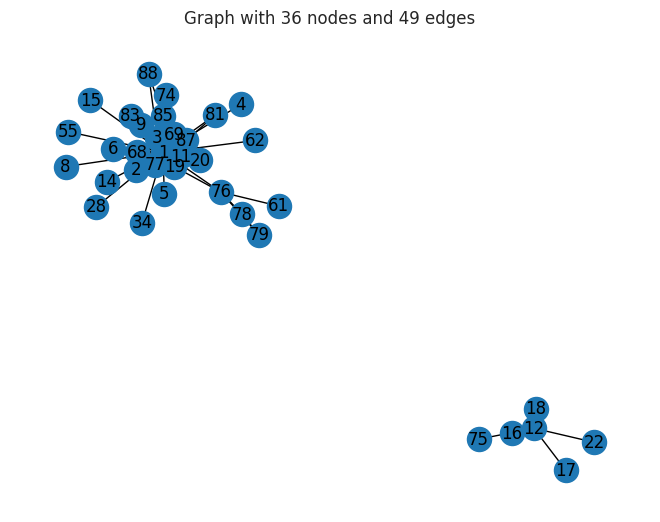

****************************************************************************************
Graph for phase: 8


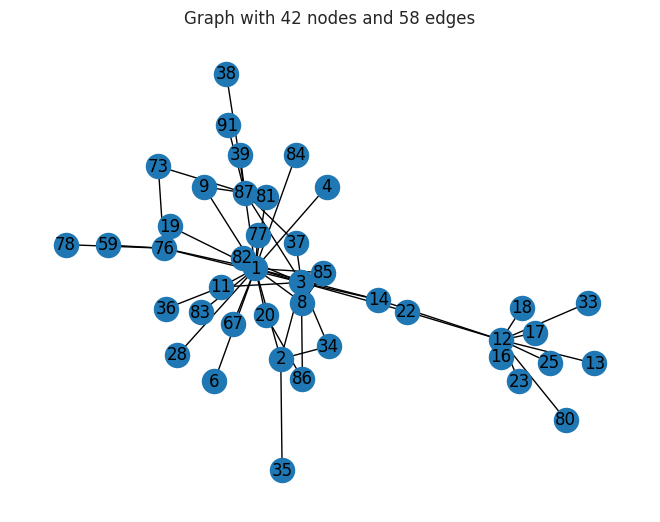

****************************************************************************************
Graph for phase: 9


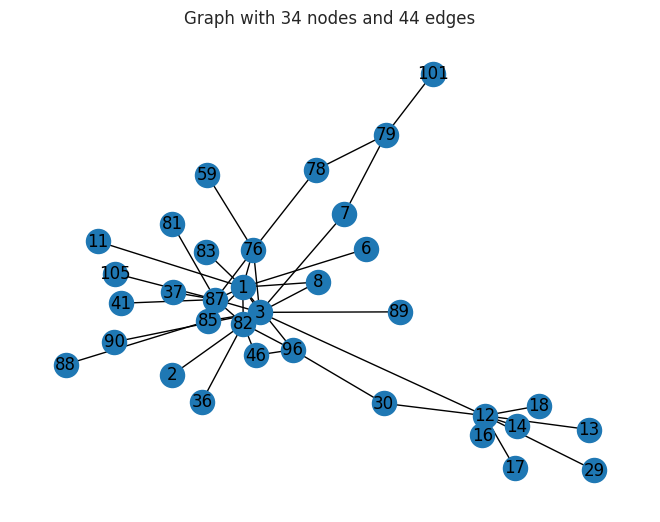

****************************************************************************************
Graph for phase: 10


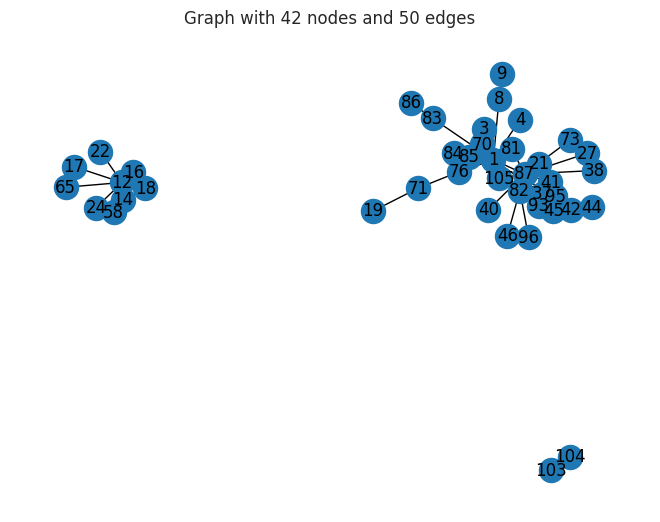

****************************************************************************************
Graph for phase: 11


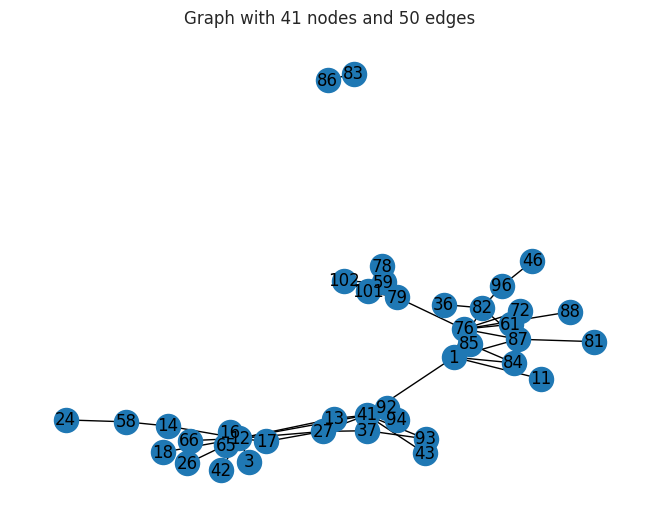

In [17]:
for i, g in enumerate(graphs):
    print("****************************************************************************************")

    print("Graph for phase:", i + 1)

    nx.draw(g, with_labels = True)

    plt.title(str(g))

    plt.show()

## **Centrality Measures**

Let us now explore the various centrality measures for the above graphs.

### **a. Degree Centrality**

- Let us now calculate the degree centrality

In [18]:
# Let us store the degree centralities for each node of a graph in a dictionary
deg_cen = {}

for g in graphs:
    deg_cen[g] = nx.degree_centrality(g)

In [19]:
# Let us look at the deg_cen dictionary
deg_cen

{<networkx.classes.graph.Graph at 0x7d8f35acf410>: {1: 0.8571428571428571,
  4: 0.07142857142857142,
  89: 0.14285714285714285,
  83: 0.14285714285714285,
  3: 0.14285714285714285,
  5: 0.07142857142857142,
  88: 0.2857142857142857,
  85: 0.21428571428571427,
  90: 0.07142857142857142,
  2: 0.07142857142857142,
  7: 0.07142857142857142,
  54: 0.07142857142857142,
  6: 0.21428571428571427,
  64: 0.07142857142857142,
  8: 0.07142857142857142},
 <networkx.classes.graph.Graph at 0x7d8f35acaed0>: {1: 0.8260869565217391,
  89: 0.13043478260869565,
  83: 0.08695652173913043,
  3: 0.13043478260869565,
  5: 0.043478260869565216,
  88: 0.13043478260869565,
  85: 0.08695652173913043,
  90: 0.043478260869565216,
  86: 0.043478260869565216,
  2: 0.043478260869565216,
  7: 0.043478260869565216,
  6: 0.043478260869565216,
  64: 0.08695652173913043,
  8: 0.13043478260869565,
  55: 0.043478260869565216,
  10: 0.08695652173913043,
  56: 0.043478260869565216,
  97: 0.043478260869565216,
  47: 0.043478260

### **b. Eigenvector, Betweenness, and Closeness Centrality measures**

In [20]:
# Similarily, we can generate other centrality measures
# Let us try all the measures that we learnt

# Eigenvector Centrality
eig_cen = {}

for g in graphs:
    eig_cen[g] = nx.eigenvector_centrality(g)

# Betweenness Centrality
betw_cen = {}

for g in graphs:
    betw_cen[g] = nx.betweenness_centrality(g)

# Closeness Centrality
clo_cen = {}

for g in graphs:
    clo_cen[g] = nx.closeness_centrality(g)

**Observations:**

- We have now created the dictionaries with the centrality measures
- The dictionaries are deg_cen, eig_cen, betw_cen, and clo_cen.
- We can sort the dictionaries, in descending order, to obtain the nodes that are the most important.

In [21]:
# Let us now sort the degree centrality measure and identify the important nodes

for ix, g in enumerate(graphs):
    temp_dict = {}
    for w in sorted(deg_cen[g], key = deg_cen[g].get, reverse = True):
        temp_dict[w] = deg_cen[g][w]
    print("Sorted importance of nodes in terms of deg_cen for Phase {} is {}".format(ix + 1, list(temp_dict.keys())[:5]))
    print()

Sorted importance of nodes in terms of deg_cen for Phase 1 is [1, 88, 85, 6, 89]

Sorted importance of nodes in terms of deg_cen for Phase 2 is [1, 89, 3, 88, 8]

Sorted importance of nodes in terms of deg_cen for Phase 3 is [1, 3, 83, 9, 49]

Sorted importance of nodes in terms of deg_cen for Phase 4 is [1, 83, 3, 89, 85]

Sorted importance of nodes in terms of deg_cen for Phase 5 is [1, 12, 3, 31, 89]

Sorted importance of nodes in terms of deg_cen for Phase 6 is [1, 3, 12, 76, 85]

Sorted importance of nodes in terms of deg_cen for Phase 7 is [1, 3, 76, 12, 85]

Sorted importance of nodes in terms of deg_cen for Phase 8 is [1, 3, 12, 87, 76]

Sorted importance of nodes in terms of deg_cen for Phase 9 is [3, 1, 12, 87, 82]

Sorted importance of nodes in terms of deg_cen for Phase 10 is [1, 87, 37, 12, 82]

Sorted importance of nodes in terms of deg_cen for Phase 11 is [12, 41, 1, 76, 79]



- We generated the degree centrality based top 5 most important nodes in each phase.
- We can go ahead and repeat the same exercise for other centrality measures.

## **Understanding the variation of node importance across phases**

- From the above analysis, we figure out that some nodes appear to be more important than others, and we will focus our attention on analyzing those nodes.

- Let us take out Node1, Node3, and Node12 and visualize their importance across phases. We will look at the betweenness and degree centrality only. You are encouraged to try out the same for other measures.

In [22]:
# Let us first start with node 1

# Node 1
node1_deg = []

phases = []

for ix, g in enumerate(graphs):
    node1_deg.append(deg_cen[g][1]*100)
    phases.append(ix + 1)

node1_bet = []

for ix, g in enumerate(graphs):
    node1_bet.append(betw_cen[g][1]*100)

# Now, let us calculate the same for node 3 and 12 as well

# Node 3
node3_deg = []

for ix, g in enumerate(graphs):
    node3_deg.append(deg_cen[g][3]*100)

node3_bet = []

for ix, g in enumerate(graphs):
    node3_bet.append(betw_cen[g][3]*100)

# Node 12
node12_deg = []

for ix, g in enumerate(graphs):
    if (12 in deg_cen[g].keys()):
        node12_deg.append(deg_cen[g][12]*100)
    else:
        node12_deg.append(None)

node12_bet = []

for ix, g in enumerate(graphs):
    if (12 in betw_cen[g].keys()):
        node12_bet.append(betw_cen[g][12]*100)
    else:
        node12_bet.append(None)

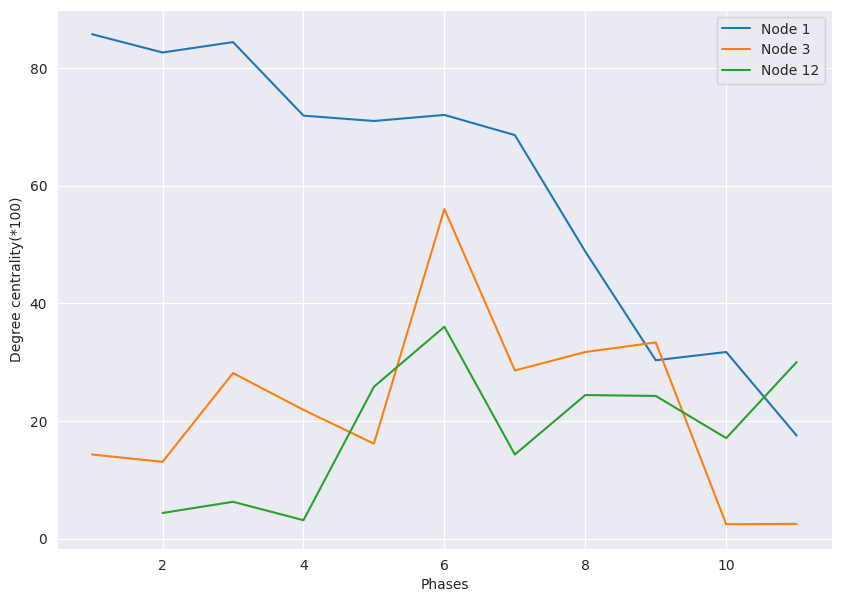

In [23]:
# Now, let us plot the importance of nodes across phases

# Ploting Degree centrality for nodes 1, 3, and 12
plt.figure(figsize = (10, 7))

plt.plot(phases, node1_deg, label = 'Node 1')

plt.plot(phases, node3_deg, label = 'Node 3')

plt.plot(phases, node12_deg, label = 'Node 12')

plt.ylabel('Degree centrality(*100)')

plt.xlabel('Phases')

plt.legend()

plt.show()

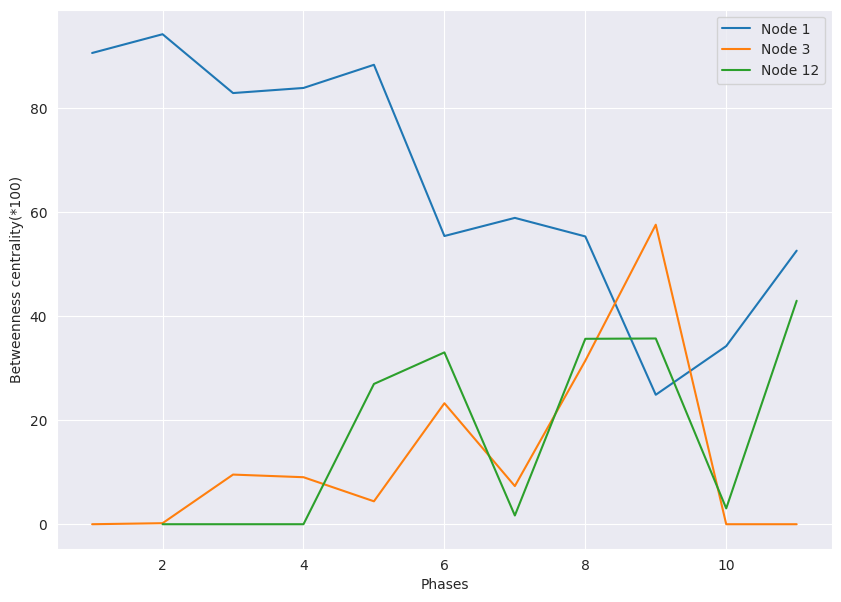

In [25]:
# Plotting the Betweenness Centrality for nodes 1, 3, and 12

plt.figure(figsize = (10, 7))

plt.plot(phases, node1_bet,  label = 'Node 1')

plt.plot(phases, node3_bet, label = 'Node 3')

plt.plot(phases, node12_bet, label = 'Node 12')

plt.ylabel('Betweenness centrality(*100)')

plt.xlabel('Phases')

plt.legend()

plt.show()

## **Conclusion:**

- We carried out the analysis on the network and figured out techniques to read adjacency matrices into graphs.
- We later visualized the graphs, created centrality measures, and identified the important nodes - N1 (Daniel Serero), N3 (Pierre Perlini), N12 (Ernesto Morales).
- We studied and plotted the variation in the centrality of the important nodes across phases in a bid to understand the affect of disruption in the network.

## **Bonus: We can highlight the important nodes in graphs**

- Let's have a look at the phase 2 graph: graph2

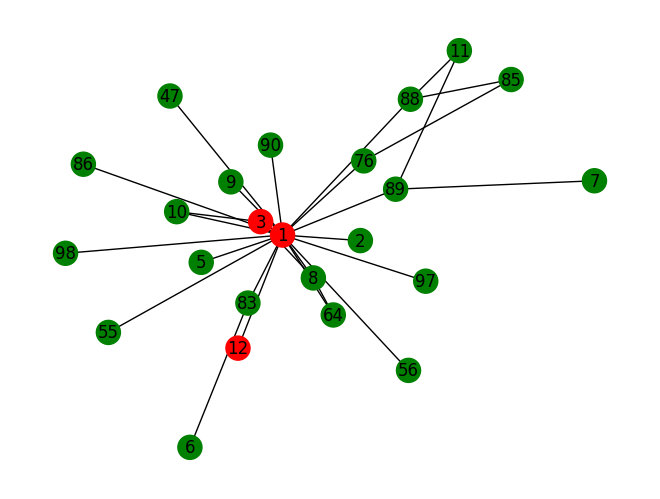

In [ ]:
graph2 = nx.from_pandas_adjacency(P2)

color = []

for node in graph2:
    if (node == 1 or node == 12  or node == 3):
        color.append('red')
    else:
        color.append('green')

nx.draw_spring(graph2, node_color = color, with_labels = True)

- The important nodes, i.e., nodes 1, 3, and 12 have been marked as red.